<a href="https://colab.research.google.com/github/alanJoshiGeorge/Event-Team-Builder/blob/main/decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "diabetes_risk.csv"

df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "mansiaggarwal88/diabetes-risk-prediction",
  file_path,
)

print("First 5 records:", df.head())

/tmp/ipykernel_1852/1958085541.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 1.47M/1.47M [00:00<00:00, 4.64MB/s]


First 5 records:    patient_id  age  gender       city   bmi family_history_diabetes  \
0           1   47  Female     Mumbai  26.5                     Yes   
1           2   53  Female     Mumbai  20.5                     Yes   
2           3   47    Male      Thane  31.3                      No   
3           4   41    Male  Bengaluru  22.8                      No   
4           5   57  Female  Bengaluru  16.7                      No   

  physical_activity_level       diet_type smoking_status alcohol_consumption  \
0               Sedentary      Vegetarian          Never               Never   
1                Moderate      Vegetarian          Never               Never   
2                Moderate  Non-Vegetarian        Current             Regular   
3               Sedentary  Non-Vegetarian          Never               Never   
4               Sedentary  Non-Vegetarian        Current          Occasional   

   hours_sleep_per_night  stress_level  fasting_blood_sugar  hba1c_level  \

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Remove patient_id if it exists
df = df.drop(columns=["patient_id"], errors="ignore")

# Separate features and target
X = df.drop(columns=["diabetes_risk"])
y = df["diabetes_risk"].map({
    "Low": 0,
    "Moderate": 1,
    "High": 2
})

# Check target encoding
print("Target values:")
print(y.value_counts().sort_index())

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("\nTraining data:")
print("Before preprocessing:", X_train.shape)
print("After preprocessing:", X_train_processed.shape)

print("\nTesting data:")
print("Before preprocessing:", X_test.shape)
print("After preprocessing:", X_test_processed.shape)



Target values:
diabetes_risk
0    9000
1    3750
2    2250
Name: count, dtype: int64

Numerical features:
['age', 'bmi', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm']

Categorical features:
['gender', 'city', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption', 'income_bracket']

Training data:
Before preprocessing: (12000, 17)
After preprocessing: (12000, 48)

Testing data:
Before preprocessing: (3000, 17)
After preprocessing: (3000, 48)


--- Random Forest Overall Performance ---
Train Accuracy:    0.9999
Test Accuracy:     0.7827
Precision (Macro): 0.7542
Recall (Macro):    0.7125
F1 Score (Macro):  0.7304
F1 Score (Weight): 0.7788


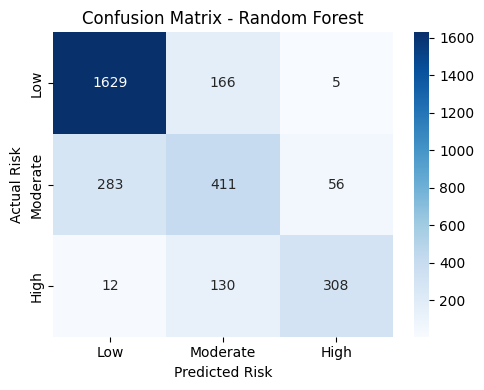


Top 10 Most Important Features:
                    Feature  Importance
        fasting_blood_sugar    0.231890
                hba1c_level    0.219881
                        age    0.067921
                        bmi    0.062933
     waist_circumference_cm    0.060952
    blood_pressure_systolic    0.041775
   blood_pressure_diastolic    0.036781
      hours_sleep_per_night    0.034127
               stress_level    0.031615
family_history_diabetes_Yes    0.008729


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Initialize and train Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train_processed, y_train)

# 2. Make predictions
y_pred_train = rf_model.predict(X_train_processed)
y_pred_test = rf_model.predict(X_test_processed)

# 3. Overall Model Performance Metrics
print("--- Random Forest Overall Performance ---")
print(f"Train Accuracy:    {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision (Macro): {precision_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"Recall (Macro):    {recall_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"F1 Score (Macro):  {f1_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"F1 Score (Weight): {f1_score(y_test, y_pred_test, average='weighted'):.4f}")

# 4. Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_test),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Moderate", "High"],
    yticklabels=["Low", "Moderate", "High"]
)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.tight_layout()
plt.show()

# 5. Extract Feature Importances
encoded_cat_features = (
    preprocessor.named_transformers_["cat"]
    .named_steps["encoder"]
    .get_feature_names_out(categorical_features)
)
all_feature_names = numerical_features + list(encoded_cat_features)

feature_importances = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importances.head(10).to_string(index=False))

--- Decision Tree Overall Performance ---
Train Accuracy:    0.7839
Test Accuracy:     0.7710
Precision (Macro): 0.7413
Recall (Macro):    0.7164
F1 Score (Macro):  0.7258
F1 Score (Weight): 0.7744


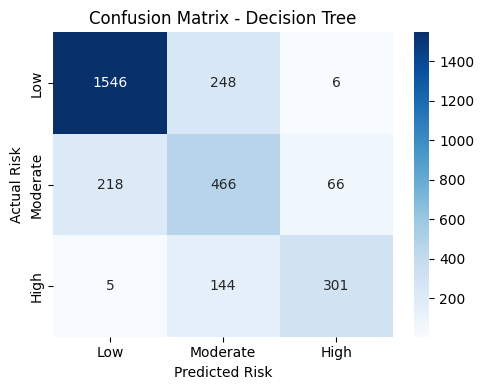


Top 10 Most Important Features:
                 Feature  Importance
     fasting_blood_sugar    0.832465
             hba1c_level    0.089809
                     age    0.057277
                     bmi    0.018000
  waist_circumference_cm    0.002144
   hours_sleep_per_night    0.000305
 blood_pressure_systolic    0.000000
            stress_level    0.000000
blood_pressure_diastolic    0.000000
           gender_Female    0.000000


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 1. Initialize and train Decision Tree
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    min_samples_split=10,
    random_state=42
)
dt_model.fit(X_train_processed, y_train)

# 2. Make predictions
y_pred_train = dt_model.predict(X_train_processed)
y_pred_test = dt_model.predict(X_test_processed)

# 3. Overall Model Performance Metrics
print("--- Decision Tree Overall Performance ---")
print(f"Train Accuracy:    {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test Accuracy:     {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision (Macro): {precision_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"Recall (Macro):    {recall_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"F1 Score (Macro):  {f1_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"F1 Score (Weight): {f1_score(y_test, y_pred_test, average='weighted'):.4f}")

# 4. Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_test),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Moderate", "High"],
    yticklabels=["Low", "Moderate", "High"]
)
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.tight_layout()
plt.show()

# 5. Feature Importances
encoded_cat_features = (
    preprocessor.named_transformers_["cat"]
    .named_steps["encoder"]
    .get_feature_names_out(categorical_features)
)
all_feature_names = numerical_features + list(encoded_cat_features)

feature_importances = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": dt_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nTop 10 Most Important Features:")
print(feature_importances.head(10).to_string(index=False))

--- Overall Model Performance ---
Train Accuracy: 0.8340
Test Accuracy:  0.7863
Macro F1 Score: 0.7305
Weighted F1:    0.7826
Train R2 Score: 0.6740
Test R2 Score:  0.5769


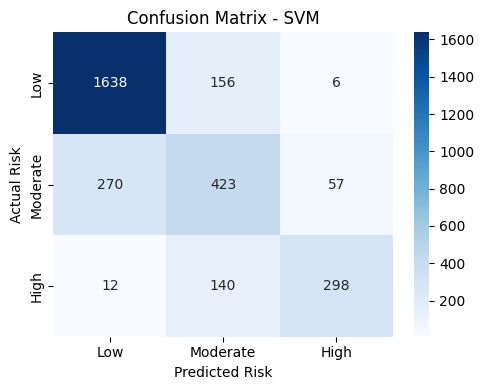

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, r2_score, confusion_matrix

# 1. Initialize and train Support Vector Classifier
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)

svm_model.fit(X_train_processed, y_train)

# 2. Predictions
y_pred_train = svm_model.predict(X_train_processed)
y_pred_test = svm_model.predict(X_test_processed)

# 3. Model Performance Metrics (Including R2)
print("--- Overall Model Performance ---")
print(f"Train Accuracy: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Test Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Macro F1 Score: {f1_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"Weighted F1:    {f1_score(y_test, y_pred_test, average='weighted'):.4f}")
print(f"Train R2 Score: {r2_score(y_train, y_pred_train):.4f}")
print(f"Test R2 Score:  {r2_score(y_test, y_pred_test):.4f}")

# 4. Plot Confusion Matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_test),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Moderate", "High"],
    yticklabels=["Low", "Moderate", "High"]
)
plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.tight_layout()
plt.show()

Using Colab cache for faster access to the 'insurance' dataset.
--- Medical Insurance Charges Regression Performance ---
        Model  Train R2  Test R2  MAE ($)  RMSE ($)
Decision Tree    0.8811   0.8334  2911.16   5085.06
          SVR    0.6741   0.6915  3014.58   6920.60
Random Forest    0.9750   0.8647  2541.61   4582.97


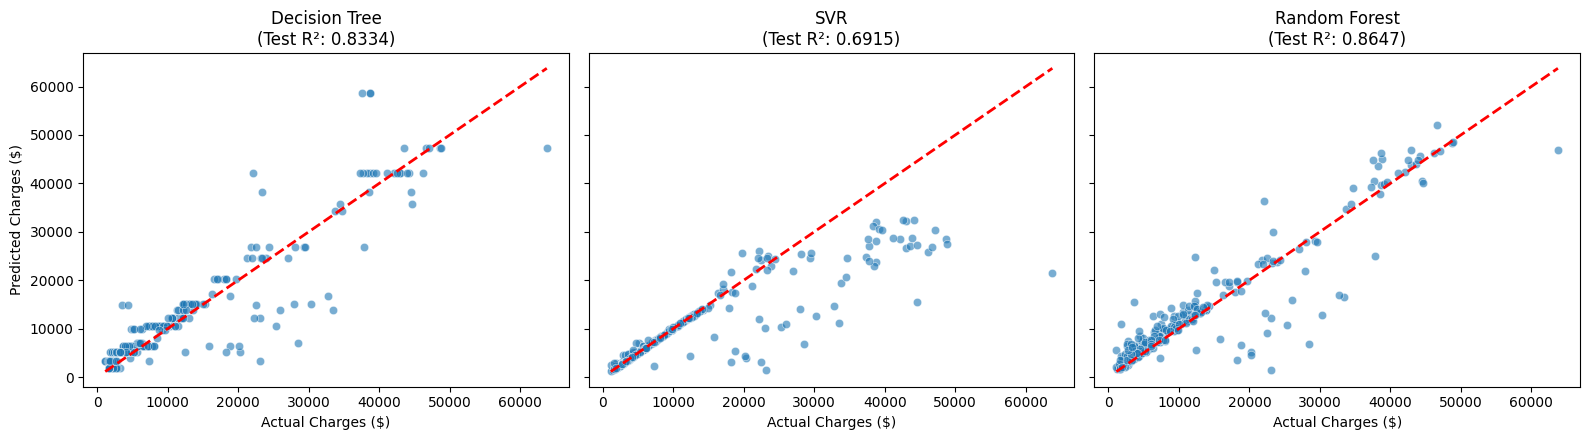


Top Feature Importances:
         Feature  DT Importance  RF Importance
       smoker_no       0.690615       0.451506
             bmi       0.179083       0.213154
      smoker_yes       0.000000       0.157113
             age       0.117291       0.133897
        children       0.007418       0.019255
region_northeast       0.002197       0.005162
region_southeast       0.000000       0.004391
region_northwest       0.003396       0.004145
      sex_female       0.000000       0.004083
        sex_male       0.000000       0.004031
region_southwest       0.000000       0.003264


In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Load Data (Updated using dataset_load to avoid DeprecationWarning)
file_path = "insurance.csv"
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "mirichoi0218/insurance",
    file_path
)

# 2. Separate Features and Target
X = df.drop(columns=["charges"])
y = df["charges"]

# 3. Identify Numerical and Categorical Columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

# 4. Pipelines
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 5. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Fit and Transform Preprocessing
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 6. Initialize Regression Models
models = {
    "Decision Tree": DecisionTreeRegressor(max_depth=5, min_samples_split=10, random_state=42),
    "SVR": SVR(kernel="rbf", C=1000, epsilon=10),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

# 7. Train and Evaluate Models
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train)
    y_pred_train = model.predict(X_train_processed)
    y_pred_test = model.predict(X_test_processed)

    predictions[name] = y_pred_test

    results.append({
        "Model": name,
        "Train R2": round(r2_score(y_train, y_pred_train), 4),
        "Test R2": round(r2_score(y_test, y_pred_test), 4),
        "MAE ($)": round(mean_absolute_error(y_test, y_pred_test), 2),
        "RMSE ($)": round(np.sqrt(mean_squared_error(y_test, y_pred_test)), 2)
    })

# Print Performance Table
results_df = pd.DataFrame(results)
print("--- Medical Insurance Charges Regression Performance ---")
print(results_df.to_string(index=False))

# 8. Plot Actual vs Predicted Charges
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, (name, y_pred) in zip(axes, predictions.items()):
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, ax=ax)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
    test_r2_val = results_df.loc[results_df["Model"] == name, "Test R2"].values[0]
    ax.set_title(f"{name}\n(Test R²: {test_r2_val})")
    ax.set_xlabel("Actual Charges ($)")
    ax.set_ylabel("Predicted Charges ($)")

plt.tight_layout()
plt.show()

# 9. Extract Top Feature Importances (Tree Models)
encoded_cat_features = (
    preprocessor.named_transformers_["cat"]
    .named_steps["encoder"]
    .get_feature_names_out(categorical_features)
)
all_feature_names = numerical_features + list(encoded_cat_features)

feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "DT Importance": models["Decision Tree"].feature_importances_,
    "RF Importance": models["Random Forest"].feature_importances_
}).sort_values(by="RF Importance", ascending=False)

print("\nTop Feature Importances:")
print(feature_importance_df.to_string(index=False))

Using Colab cache for faster access to the 'insurance' dataset.
--- Stacking Regressor Performance ---
Train R² Score: 0.9380
Test R² Score:  0.8643
MAE ($):        2592.47
RMSE ($):       4589.33


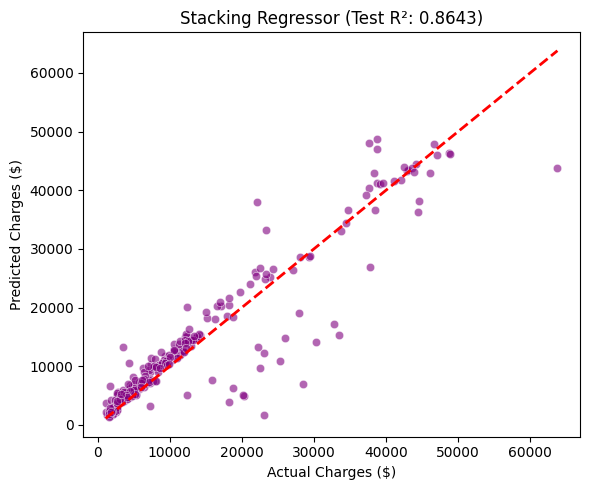

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Ensembles and Base Models
from sklearn.ensemble import StackingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.linear_model import Ridge

# Metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Load Data
file_path = "insurance.csv"
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "mirichoi0218/insurance",
    file_path
)

# 2. Features and Target Split
X = df.drop(columns=["charges"])
y = df["charges"]

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

# 3. Preprocessing Pipelines
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 5. Define Base Models (Level 0)
base_models = [
    ("dt", DecisionTreeRegressor(max_depth=5, min_samples_split=10, random_state=42)),
    ("svr", SVR(kernel="rbf", C=1000, epsilon=10)),
    ("rf", RandomForestRegressor(n_estimators=100, random_state=42))
]

# 6. Initialize Stacking Regressor with Ridge Meta-Model (Level 1)
# Uses 5-fold cross-validation internally to train the meta-model without leakage
stacking_model = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(alpha=1.0),
    cv=5
)

# 7. Fit and Evaluate Stacking Regressor
stacking_model.fit(X_train_processed, y_train)

y_pred_train = stacking_model.predict(X_train_processed)
y_pred_test = stacking_model.predict(X_test_processed)

# Metrics
train_r2 = r2_score(y_train, y_pred_train)
test_r2 = r2_score(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("--- Stacking Regressor Performance ---")
print(f"Train R² Score: {train_r2:.4f}")
print(f"Test R² Score:  {test_r2:.4f}")
print(f"MAE ($):        {mae:.2f}")
print(f"RMSE ($):       {rmse:.2f}")

# 8. Plot Actual vs Predicted Values
plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.6, color="purple")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
plt.title(f"Stacking Regressor (Test R²: {test_r2:.4f})")
plt.xlabel("Actual Charges ($)")
plt.ylabel("Predicted Charges ($)")
plt.tight_layout()
plt.show()

In [ ]:
import joblib
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Load Weather Dataset directly from direct raw CSV URL
url = "https://raw.githubusercontent.com/vega/vega-datasets/main/data/seattle-weather.csv"
df = pd.read_csv(url)

print("Dataset Preview:")
print(df.head())

# Features and Target
# Features: precipitation, temp_max, temp_min, wind
X = df.drop(columns=["date", "weather"])
y = df["weather"]

numerical_cols = X.columns.tolist()

# 2. Build Preprocessing & Logistic Regression Pipeline
preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), numerical_cols)]
)

model = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

# 3. Train / Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Model Training & Evaluation
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\nModel Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# 5. Save Model
joblib.dump(model, "seattle_weather_model.pkl")
print("Model saved as 'seattle_weather_model.pkl'!")

Dataset Preview:
         date  precipitation  temp_max  temp_min  wind  weather
0  2012-01-01            0.0      12.8       5.0   4.7  drizzle
1  2012-01-02           10.9      10.6       2.8   4.5     rain
2  2012-01-03            0.8      11.7       7.2   2.3     rain
3  2012-01-04           20.3      12.2       5.6   4.7     rain
4  2012-01-05            1.3       8.9       2.8   6.1     rain

Model Evaluation:
Accuracy: 0.7815699658703071

Classification Report:
               precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00        11
         fog       0.00      0.00      0.00        20
        rain       0.91      0.83      0.87       129
        snow       0.50      0.20      0.29         5
         sun       0.70      0.95      0.80       128

    accuracy                           0.78       293
   macro avg       0.42      0.39      0.39       293
weighted avg       0.71      0.78      0.74       293

Model saved as 'seattle_weather_model

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
import gradio as gr
import joblib
import pandas as pd

# Load saved pipeline model
model = joblib.load("seattle_weather_model.pkl")


def predict_weather(precipitation, temp_max, temp_min, wind):
    # Construct input dataframe matching exact training columns
    input_df = pd.DataFrame(
        {
            "precipitation": [float(precipitation)],
            "temp_max": [float(temp_max)],
            "temp_min": [float(temp_min)],
            "wind": [float(wind)],
        }
    )

    # Predictions & Probabilities
    predicted_condition = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]
    classes = model.classes_

    # Map class labels to percentage probabilities for Gradio visualizer
    prob_dict = {
        cls.capitalize(): float(prob) for cls, prob in zip(classes, probabilities)
    }

    # Custom UI status banner
    status_emoji = {
        "rain": "🌧️ RAIN",
        "sun": "☀️ SUNNY",
        "fog": "🌫️ FOGGY",
        "drizzle": "🌦️ DRIZZLE",
        "snow": "❄️ SNOW",
    }.get(predicted_condition.lower(), predicted_condition.upper())

    return f"Predicted Condition: {status_emoji}", prob_dict


# -----------------------------
# Gradio Blocks Interface
# -----------------------------
with gr.Blocks(title="Live Weather Condition Predictor") as demo:

    gr.Markdown(
        """
        # 🌤️ Live Weather Prediction App
        Enter local meteorological parameters below to estimate weather condition probabilities via Logistic Regression.
        """
    )

    with gr.Row():
        with gr.Column():
            precipitation = gr.Slider(
                minimum=0.0,
                maximum=60.0,
                value=0.0,
                step=0.1,
                label="Precipitation (mm)",
            )
            temp_max = gr.Number(
                label="Max Temperature (°C)", value=22.0, precision=1
            )
            temp_min = gr.Number(
                label="Min Temperature (°C)", value=11.0, precision=1
            )
            wind = gr.Slider(
                minimum=0.0,
                maximum=15.0,
                value=3.2,
                step=0.1,
                label="Wind Speed (m/s)",
            )

            predict_btn = gr.Button("🔮 Predict Weather", variant="primary")

        with gr.Column():
            output_text = gr.Textbox(
                label="Predicted Weather Outcome", interactive=False
            )
            output_chart = gr.Label(
                label="Class Probabilities Breakdown", num_top_classes=5
            )

    # Event trigger (Supports button click & live input updates)
    predict_btn.click(
        fn=predict_weather,
        inputs=[precipitation, temp_max, temp_min, wind],
        outputs=[output_text, output_chart],.
    )


demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b13599b5153774cdad.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
y.value_counts()

,count
weather,
rain,641
sun,640
fog,101
drizzle,53
snow,26
